05 ScoliGaitX (WACV 2026): what is inside, what holds up, what we can take

the paper is Vishwakarma & Nigam, *ScoliGaitX: A Deep Multi-Modal Fusion Network for Scoliosis Assessment via Gait Video Analysis*, WACV 2026 (the PDF is in this folder). they claim **89.05 / 89.22 / 92.48** (acc / Sen / Spe) on the 1:1:8 split, vs ScoNet-MT 82.0 / 99.0 / 76.5. the code is not public yet ("We will publicly release our complete source code").

in part A i read the paper: in step 1 the architecture in one table, in step 2 the numbers read critically, and in step 3 where ScoliGaitX sits on my ScoNet-MT trade-off curve. in part B i try the ideas on my own data: in step 4 GEI and GEI-subtract, in step 5 optical flow on silhouettes, in step 6 the Align Gate Fusion (AGF) module written out, and in step 7 a mini training with silhouette only vs + GEI-subtract (2 ways of fusing). step 8 is the analysis.

part A: the paper

step 1: the architecture (sections 3.1-3.5 and 4.3 of the paper)

| piece | what it does |
|---|---|
| 3 inputs | **S** silhouettes, **O** optical flow (precomputed, horizontal + vertical), **G** GEI-subtract `f_i - mean(f)` (computed on the fly) |
| FES | one stream per input: 4 blocks of **3D CNN** (GaitGL style), so time is mixed inside the backbone (ScoNet's ResNet9 is 2D, frame by frame) |
| AGF x 2 | fuse S with O, and S with G: concat -> conv (2C -> C) = `F_mid` -> global average pool -> conv -> sigmoid = `W` -> `Y = W * F1 + (1 - W) * F2` -> concat(`F_mid`, `Y`) -> conv (2C -> C) |
| STFH x 5 | one head for each of S, O, G, SO, SG: set pooling = **mean** over time, GeM horizontal pooling (p = 6.5), FC -> triplet feature, BNNeck -> class logits |
| loss | `1.2 * triplet + 1.0 * CE`; triplet positives = **same class** (not same child like ScoNet-MT), margin 1.5; **inverse class-weighted CE** |
| training | Adam lr 1e-4, weight decay 5e-4, batch 8 x 8, 30 frames, 64 x 44 |

step 2: reading the numbers critically

these are the things i checked in the PDF.

**the metric convention is the same as ScoNet-MT.** the note under table 3 says "Sensitivity and Specificity are wrt Negative class", so Sen 89.22 = recall of negative, and Spe 92.48 = scoliosis (neutral + positive) not called negative. their bullet text in 4.2 says it the other way round ("true positives (non-scoliosis cases ...)"), which is confusing, but the numbers only make sense with the table 3 note.

**they trade negative recall for scoliosis recall.** Sen goes from 99.0 (ScoNet-MT) to 89.22, so about 22 of the 204 healthy children are now flagged. their text says the model "misclassifies only 10 negative samples compared to 59 by ScoNet-MT", but with ScoNet-MT at 99.0% negative recall only ~2 negatives can be wrong, so that sentence must count something else (i can't check the confusion matrix figure).

**most of the gain is already there without fusion.** in table 4 GaitGL with silhouettes only gets **84.65**, and their single stream ScoliGaitX-S **86.65**. both already beat ScoNet-MT (82.0) by 2.6-4.6 points with silhouettes only, and the fusion adds 86.65 -> 89.05 (+2.4). so the backbone (3D CNN), the loss (class-weighted CE, class triplet) and the optimizer explain more than the extra modalities. and the single modality that helps most is **GEI-subtract** (S-G alone 88.25 > S-O 87.05).

**the imbalance table uses its own splits.** table 2 lists the 1:1:2 test set as 307 : 14 : 427 (pos : neu : neg), so only 14 neutrals, and these are not comparable between papers (old notebook / memory: the ratios were re-split differently by every paper). **the noise table is strange**: gaussian noise with std 0.0001 on a 0..1 silhouette is invisible, but the accuracy already drops 89.05 -> 87.72, and at std 0.05 it collapses to 32.04% with Spe 97.98 (almost everything called scoliosis). and there are **no seeds, no variance and no code**, one number per setting.

step 3: where does ScoliGaitX sit on my curve?

in notebook 01 i moved the decision border of my ScoNet-MT@16k with post-hoc logit adjustment (`tau`). here i check how close ScoliGaitX is to that curve: for its Spe (92.48), what Sen does my curve give? remember that the curve is drawn with `tau` chosen on the test set, so this is a comparison of trade-offs, not a result.

ScoliGaitX                     : acc 89.05 | Sen 89.22 | Spe 92.48
my curve at the same Spe (92.3) : acc 90.79 | Sen 91.18 | tau 0.36
TG-MILNet                      : acc 89.9  | Sen 99.5  | Spe 86.4
my curve at the same Sen (98.5) : acc 82.64 | Spe 77.80


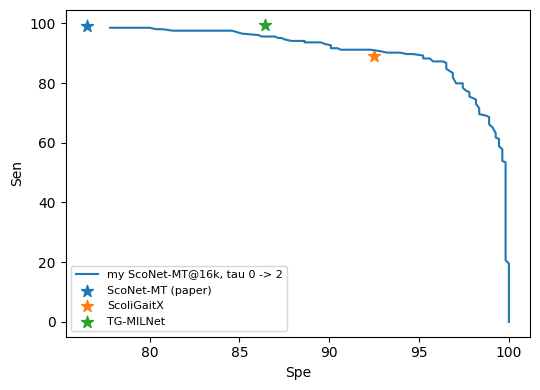

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import cv2

sys.path.insert(0, os.path.abspath(os.path.join('..', 'tools')))
from common import *

FIG_DIR = os.path.join('output', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)


def save_and_show(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=120)
    plt.show()


lg16, true16, subj16 = load_saved_logits('official', 16000)
z16 = 16 * lg16.mean(-1)
prior = np.array([596, 74, 74]) / 744
curve = []
for tau in np.arange(0, 2.01, 0.01):
    curve.append(metrics(true16, (z16 - tau * np.log(prior)).argmax(1)))
spe = np.array([m['Spe'] for m in curve])
sen = np.array([m['Sen'] for m in curve])
acc = np.array([m['acc'] for m in curve])

i = int(np.argmin(np.abs(spe - 92.48)))
print(f'ScoliGaitX                     : acc 89.05 | Sen 89.22 | Spe 92.48')
print(f'my curve at the same Spe ({spe[i]:.1f}) : acc {acc[i]:.2f} | Sen {sen[i]:.2f} | tau {i / 100:.2f}')
j = int(np.argmin(np.abs(sen - 99.5)))
print(f'TG-MILNet                      : acc 89.9  | Sen 99.5  | Spe 86.4')
print(f'my curve at the same Sen ({sen[j]:.1f}) : acc {acc[j]:.2f} | Spe {spe[j]:.2f}')

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(spe, sen, label='my ScoNet-MT@16k, tau 0 -> 2')
ax.scatter([76.5], [99.0], marker='*', s=80, label='ScoNet-MT (paper)')
ax.scatter([92.48], [89.22], marker='*', s=80, label='ScoliGaitX')
ax.scatter([86.4], [99.5], marker='*', s=80, label='TG-MILNet')
ax.set_xlabel('Spe')
ax.set_ylabel('Sen')
ax.legend(fontsize=8)
save_and_show(fig, '03_curve.png')

**at ScoliGaitX's Spe (92.48), my curve is at Spe 92.3 with Sen 91.18 and accuracy 90.79 (tau 0.36).** so my ScoNet-MT with a moved border is slightly *better* than ScoliGaitX on both Sen (+2.0) and accuracy (+1.7) at the same Spe, and in the picture ScoliGaitX sits just below my curve. so ScoliGaitX's gain over ScoNet-MT can be fully explained by a different border (they train with inverse class-weighted CE). that doesn't mean its architecture is useless, but its reported numbers don't show a better *ranking* than ScoNet-MT.

**TG-MILNet is different.** my curve doesn't even get to its Sen of 99.5 (the closest point is tau 0 with Sen 98.5, Spe 77.8, acc 82.6), and TG-MILNet's Spe 86.4 at a higher Sen is clearly above my curve, so it really ranks better (notebook 06 looks at why). caveat: my curve is one model with the border tuned on the test set, while the papers report one number each, so it's a comparison of trade-offs, not a result.

part B: the ideas on my own data

step 4: GEI and GEI-subtract

the **gait energy image** (GEI, Han & Bhanu 2005) is the mean of all frames of a sequence, `GEI = (1/T) * sum_i f_i`. it shows the average body shape (bright = always body, grey = sometimes body, e.g. swinging arms and legs).

**GEI-subtract** (ScoliGaitX eq. 1) is `g_i = f_i - GEI`, so every value is between -1 and 1. it's `+` where the frame has body but the average mostly doesn't (an arm or leg that is out right now), `-` where the average has body but this frame doesn't, and `0` for the parts that are always the same, so **the static body shape disappears**. that last point is interesting for us, because in the old notebook 03 the hard and easy neutral children differed mainly in body build (arms / trunk sides vs legs), not in anything scoliosis-like, and GEI-subtract removes exactly that static part.

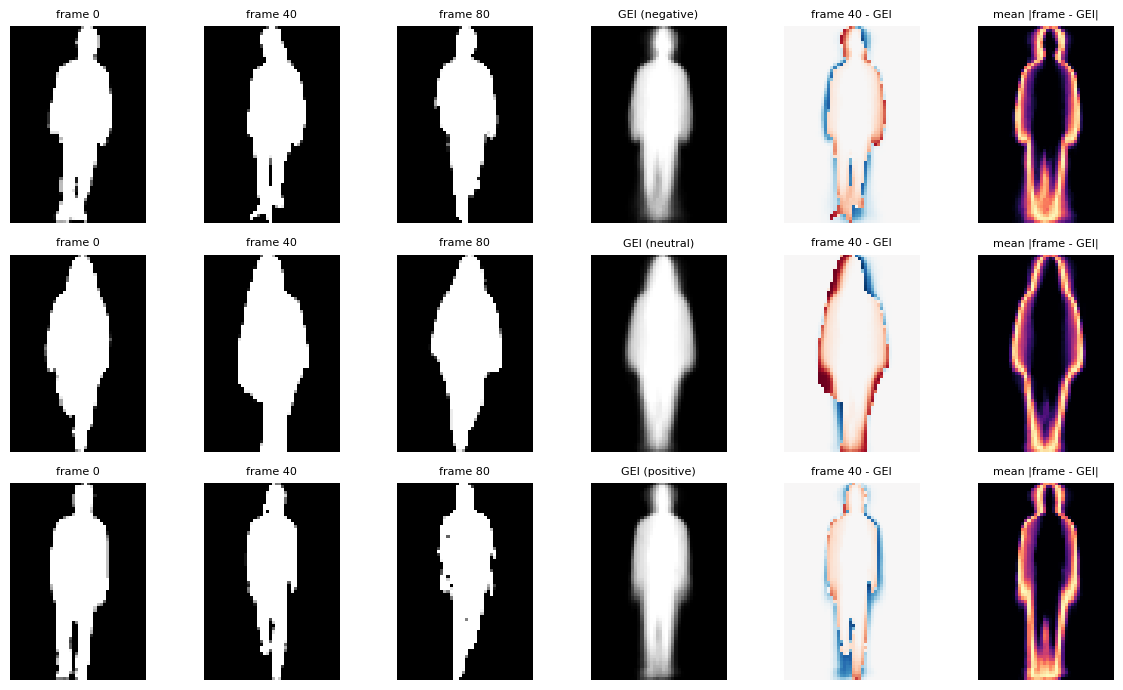

In [2]:
example = {c: subj16[true16 == c][3] for c in range(3)}
fig, ax = plt.subplots(3, 6, figsize=(12, 7))
for c in range(3):
    seq = sil_transform(load_seq(example[c]))
    gei = seq.mean(0)
    for k, t in enumerate([0, 40, 80]):
        ax[c, k].imshow(seq[t], cmap='gray')
        ax[c, k].set_title(f'frame {t}', fontsize=8)
    ax[c, 3].imshow(gei, cmap='gray')
    ax[c, 3].set_title(f'GEI ({LABEL_NAMES[c]})', fontsize=8)
    ax[c, 4].imshow(seq[40] - gei, cmap='RdBu_r', vmin=-1, vmax=1)
    ax[c, 4].set_title('frame 40 - GEI', fontsize=8)
    ax[c, 5].imshow(np.abs(seq - gei).mean(0), cmap='magma')
    ax[c, 5].set_title('mean |frame - GEI|', fontsize=8)
for a in ax.flat:
    a.axis('off')
save_and_show(fig, '04_gei_subtract.png')

the GEI is a blurred average body, sharp in the trunk and blurry at the arms and legs, which move. **`frame - GEI` is mostly a thin outline**: red where the frame sticks out of the average body, blue where it's inside, and the flat inside of the body is 0, so the body build really disappears, like the paper says. `mean |frame - GEI|` (right) shows where a child moves over the whole video: around the contour (the body sways from side to side) and much more at the lower legs and feet. these are front / back views, so the arm and leg swing is mostly hidden behind the body. the three examples look similar, i can't see the class by eye.

is there a **class difference** in how much the body moves? for 60 test children per class i compute the motion energy `mean |f_i - GEI|` in every one of the 16 strips (4 pixel rows each, like the ScoNet strips), and the AUC for neutral vs negative and positive vs negative per strip. an AUC near 0.5 means no difference.

In [3]:
def strip_energy(seq_uint8):
    seq = sil_transform(seq_uint8)
    energy = np.abs(seq - seq.mean(0)).mean(0)                 # [64, 44]
    return np.array([energy[4 * s:4 * s + 4].mean() for s in range(16)])


rng = np.random.default_rng(0)
energy, labels_e = [], []
for c in range(3):
    for s in rng.choice(subj16[true16 == c], 60, replace=False):
        energy.append(strip_energy(load_seq(s)))
        labels_e.append(c)
energy, labels_e = np.array(energy), np.array(labels_e)

print('strip | mean energy neg / neu / pos | AUC neu>neg | AUC pos>neg')
for s in range(16):
    e = energy[:, s]
    print(f'  {s + 1:2d}  | {e[labels_e == 0].mean():.3f} / {e[labels_e == 1].mean():.3f} / {e[labels_e == 2].mean():.3f}'
          f'       |   {auc(e[labels_e == 1], e[labels_e == 0]):.2f}      |   {auc(e[labels_e == 2], e[labels_e == 0]):.2f}')
total = energy.mean(1)
print('whole body | AUC neu>neg', round(auc(total[labels_e == 1], total[labels_e == 0]), 2),
      '| AUC pos>neg', round(auc(total[labels_e == 2], total[labels_e == 0]), 2))

strip | mean energy neg / neu / pos | AUC neu>neg | AUC pos>neg
   1  | 0.066 / 0.066 / 0.057       |   0.50      |   0.34
   2  | 0.067 / 0.068 / 0.059       |   0.51      |   0.37
   3  | 0.058 / 0.059 / 0.053       |   0.50      |   0.36
   4  | 0.056 / 0.058 / 0.054       |   0.54      |   0.41
   5  | 0.061 / 0.063 / 0.059       |   0.57      |   0.45
   6  | 0.067 / 0.070 / 0.065       |   0.57      |   0.45
   7  | 0.074 / 0.077 / 0.072       |   0.57      |   0.45
   8  | 0.081 / 0.085 / 0.078       |   0.57      |   0.45
   9  | 0.088 / 0.093 / 0.086       |   0.59      |   0.46
  10  | 0.075 / 0.077 / 0.074       |   0.58      |   0.51
  11  | 0.060 / 0.058 / 0.056       |   0.50      |   0.45
  12  | 0.074 / 0.071 / 0.069       |   0.45      |   0.41
  13  | 0.088 / 0.081 / 0.080       |   0.42      |   0.42
  14  | 0.103 / 0.095 / 0.097       |   0.42      |   0.45
  15  | 0.119 / 0.112 / 0.114       |   0.42      |   0.45
  16  | 0.120 / 0.111 / 0.113       |   0.29      |

**neutral vs negative: no difference in motion energy** (whole body AUC 0.49, strips between 0.42 and 0.59). the only strip a bit away from 0.5 is the feet (strip 16, AUC 0.29, so neutrals move their feet *less*). **positive vs negative: positives move LESS, mainly at the head / shoulders** (strips 1-3, AUC 0.34-0.37) and at the feet (0.35), and the whole body is AUC 0.40.

careful: "less motion energy" is not automatically scoliosis. in the paper's table 1, positive children are younger (14.3 vs 15.5 years) and lighter (48.3 vs 53.3 kg) than negatives, so body size and walking style can explain part of it. so GEI-subtract carries *some* class information for positive vs negative, but for the hard pair (neutral vs negative) it gives nothing on its own.

step 5: optical flow on silhouettes

optical flow estimates for every pixel how far it moved between two frames (`dx`, `dy`). ScoliGaitX precomputes it, but doesn't say which method. i use OpenCV's **Farneback** method on the 64 x 64 silhouettes.

> **disclaimer:** `cv2.calcOpticalFlowFarneback` is a library function, i didn't write the optical flow myself.

on a binary silhouette the inside of the body is flat white, so flow can only be measured at the **edges**. so i check how much of the flow is on the edge.

share of the flow magnitude that is within ~2 px of the silhouette edge: mean 27.7 %
mean flow magnitude per pixel inside the body (not edge): 0.907 px


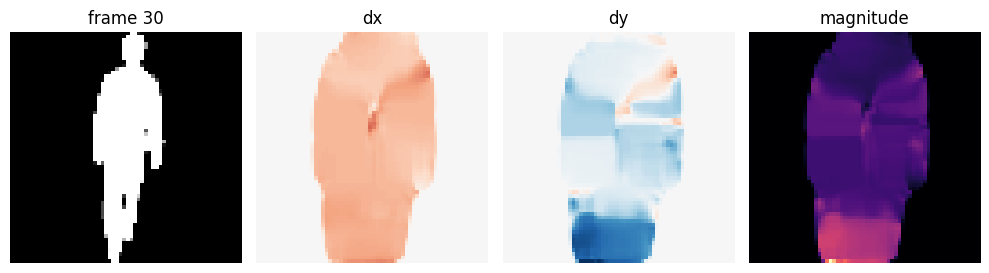

In [4]:
seq_u8 = load_seq(example[2])
flows = []
for t in range(0, 60):
    flows.append(cv2.calcOpticalFlowFarneback(seq_u8[t], seq_u8[t + 1], None, 0.5, 3, 9, 3, 5, 1.1, 0))
flows = np.array(flows)                                    # [60, 64, 64, 2]
mag = np.sqrt((flows ** 2).sum(-1))

edge = []
for t in range(60):
    body = seq_u8[t] > 127
    eroded = cv2.erode(body.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)
    dilated = cv2.dilate(body.astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)
    ring = dilated & ~eroded
    edge.append(mag[t][ring].sum() / (mag[t].sum() + 1e-9))
print('share of the flow magnitude that is within ~2 px of the silhouette edge: mean', round(100 * np.mean(edge), 1), '%')
print('mean flow magnitude per pixel inside the body (not edge):',
      round(float(np.mean([mag[t][cv2.erode((seq_u8[t] > 127).astype(np.uint8), np.ones((5, 5), np.uint8)).astype(bool)].mean() for t in range(60)])), 3), 'px')

fig, ax = plt.subplots(1, 4, figsize=(10, 3.4))
t = 30
ax[0].imshow(seq_u8[t], cmap='gray')
ax[0].set_title('frame 30')
ax[1].imshow(flows[t, ..., 0], cmap='RdBu_r', vmin=-3, vmax=3)
ax[1].set_title('dx')
ax[2].imshow(flows[t, ..., 1], cmap='RdBu_r', vmin=-3, vmax=3)
ax[2].set_title('dy')
ax[3].imshow(mag[t], cmap='magma')
ax[3].set_title('magnitude')
for a in ax:
    a.axis('off')
save_and_show(fig, '05_optical_flow.png')

**my expectation was wrong: only 27.7% of the flow magnitude is within ~2 px of the silhouette edge**, and inside the body Farneback still reports 0.9 px of motion per pixel. the reason is that Farneback fits smooth polynomials over a 9 x 9 window, so it **spreads** the edge motion into the flat white inside, where in reality there is nothing to measure. so the flow inside the body is interpolated, not observed.

so on silhouettes optical flow is a smoothed version of the edge motion: roughly the same information as GEI-subtract / frame differences, but more expensive and with made-up values inside the body. that fits their table 4, where O alone (87.05) is weaker than G alone (88.25).

step 6: the Align Gate Fusion module, written out

this is from eqs. 3-9 of the paper. there are two feature maps `F1` (silhouette stream) and `F2` (motion stream), each `[C, H, W]` for one frame. ScoliGaitX works with 3D features (time inside), and i apply the same operations **per frame** with 1 x 1 convolutions, because my backbone is 2D.

first `F_cat = concat(F1, F2)` -> `[2C, H, W]`, then `F_mid = conv(F_cat)` -> `[C, H, W]` ("align" the two modalities), then `F_gap = global average pool(F_mid)` -> `[C, 1, 1]`, and `W = sigmoid(conv(F_gap))` -> `[C, 1, 1]`, which is one number between 0 and 1 **per channel**. then `Y = W * F1 + (1 - W) * F2`, per channel a mix of the two modalities, and at the end `F_out = conv(concat(F_mid, Y))` -> `[C, H, W]`.

a small example for one channel: `F1 = 2`, `F2 = 6`, `W = 0.75` -> `Y = 0.75 * 2 + 0.25 * 6 = 3`. with `W = 1` only the silhouette counts, and with `W = 0` only the motion. because `W` comes from a *global* average, it's the same for every pixel of the frame, so AGF chooses **how much of each channel** comes from each modality, not *where*.

In [5]:
class AlignGateFusion(nn.Module):
    def __init__(self, c=512):
        super().__init__()
        self.align = nn.Conv2d(2 * c, c, 1)
        self.gate = nn.Conv2d(c, c, 1)
        self.out = nn.Conv2d(2 * c, c, 1)

    def forward(self, f1, f2):
        f_mid = self.align(torch.cat([f1, f2], 1))
        w = torch.sigmoid(self.gate(f_mid.mean((2, 3), keepdim=True)))
        y = w * f1 + (1 - w) * f2
        return self.out(torch.cat([f_mid, y], 1)), w


f1, f2 = torch.full((1, 1, 1, 1), 2.0), torch.full((1, 1, 1, 1), 6.0)
w = torch.full((1, 1, 1, 1), 0.75)
print('hand example: Y =', (w * f1 + (1 - w) * f2).item())
agf = AlignGateFusion()
out, w = agf(torch.rand(4, 512, 16, 11), torch.rand(4, 512, 16, 11))
print('AGF output', tuple(out.shape), '| gate W', tuple(w.shape), '| parameters', sum(p.numel() for p in agf.parameters()))

hand example: Y = 3.0
AGF output (4, 512, 16, 11) | gate W (4, 512, 1, 1) | parameters 1312256


step 7: mini training, does GEI-subtract help my ScoNet-MT?

i test the cheapest and the most interesting modality (GEI-subtract, the best single modality in their table 4). optical flow would need a precomputed flow for every frame, and step 5 shows it's mostly an edge signal.

| variant | input | backbone | fusion |
|---|---|---|---|
| S | silhouette | 1 ResNet9 | - |
| S+G early | 2 channels: silhouette and `f - GEI` | 1 ResNet9 (first conv takes 2 channels) | at the input |
| S+G AGF | silhouette and `f - GEI` | 2 ResNet9 (one per input) | AGF on the 512-channel maps |

the GEI is computed **from the frames the model gets** (like ScoliGaitX, "on the fly"), so the 16 frames of the clip, in training and in the clip test, and a GEI of 16 frames is noisier than one of 300 frames. both ResNet9 start from GaitBase, and for `S+G early` the new 2nd input channel of the first conv starts at **zero**, so at iteration 0 the model is exactly `S`. the children, sampler, seed, iterations and loss (triplet + CE) are the same as in notebooks 03 and 04, and i use only one head (ScoliGaitX uses 5 heads with a loss on each, but i keep one to change only one thing).

In [6]:
def gei_subtract(sils):
    """sils [n, s, h, w] -> [n, s, h, w]: every frame minus the mean of its own sequence"""
    return sils - sils.mean(1, keepdim=True)


class ScoNetGEI(ScoNetMT):
    def __init__(self, mode='S'):
        super().__init__()
        self.mode = mode
        if mode == 'S+G early':
            self.backbone.conv1 = nn.Conv2d(2, 64, 3, 1, 1, bias=False)
        if mode == 'S+G AGF':
            self.backbone_g = ResNet9()
            self.agf = AlignGateFusion()
            init_parameters(self.agf)

    def forward(self, sils):
        if self.mode == 'S':
            return super().forward(sils)
        g = gei_subtract(sils)
        if self.mode == 'S+G early':
            f = encode_frames(self.backbone, torch.stack([sils, g], 2))       # [n, s, 512, 16, 11]
            gate = None
        else:
            f_s = encode_frames(self.backbone, sils)
            f_g = encode_frames(self.backbone_g, g)
            n, s = f_s.shape[:2]
            fused, gate = self.agf(f_s.flatten(0, 1), f_g.flatten(0, 1))
            f = fused.view(n, s, *fused.shape[1:])
        embed = self.fcs(horizontal_pooling(f.max(1)[0]))
        out = {'embed': embed, 'logits': self.bnnecks(embed)}
        if gate is not None:
            out['gate'] = gate.view(f.shape[0], f.shape[1], -1).mean(1)      # [n, 512], mean over frames
        return out


def build(mode):
    set_seed(0)
    model = ScoNetGEI(mode)
    if mode == 'S+G early':
        tmp = ResNet9()
        load_gaitbase_backbone(tmp)
        sd = tmp.state_dict()
        w1 = sd['conv1.weight']                                              # [64, 1, 3, 3]
        sd['conv1.weight'] = torch.cat([w1, torch.zeros_like(w1)], 1)        # 2nd channel starts at 0
        model.backbone.load_state_dict(sd)
    else:
        load_gaitbase_backbone(model.backbone)
    if mode == 'S+G AGF':
        load_gaitbase_backbone(model.backbone_g)
    return model


for mode in ['S', 'S+G early', 'S+G AGF']:
    m = build(mode)
    print(f'{mode:10s} parameters {sum(p.numel() for p in m.parameters()) / 1e6:.2f} M')

S          parameters 7.01 M
S+G early  parameters 7.02 M


S+G AGF    parameters 13.22 M


**how the mini models are tested (important).** the models are trained on clips of 16 random frames. if i test them with all 300 frames at once, the max over frames gives much bigger values than the model ever saw in training. i checked this once on a plain ScoNet-MT mini model (same children as here): with all 300 frames it got **36.7%** (almost every child "negative"), and with 10 random 16-frame clips averaged it got **65.8%**. that's probably also why every test child became "neutral" in the checkpoint_1 self_learning notebooks. so `predict_mini` (in `tools/common.py`) now tests like training: **10 random clips of 16 frames per child, with the class scores averaged over the clips**. the full ScoNet-MT doesn't have this problem as much, because it trains for 16,000 iterations on 30 frames.

the newly added modules (heads, strip weights, attention, fusion) learn with lr 1e-3 and the pretrained ResNet9 with 1e-4, because in a first try with 1e-4 everywhere the new modules hardly moved in 500 iterations.

In [7]:
split = load_split('118')
mini_train = load_items(pick_children(split['TRAIN_SET'], {'negative': 40, 'neutral': 40, 'positive': 40}, seed=0))
mini_test = load_items(pick_children(split['TEST_SET'], {'negative': 40, 'neutral': 40, 'positive': 40}, seed=0))

mini = {}
for mode in ['S', 'S+G early', 'S+G AGF']:
    print('---', mode)
    model = build(mode)
    train_mini(model, mini_train, balanced=True, seed=0, log_every=250)
    y, scores, raw = predict_mini(model, mini_test)
    mini[mode] = (y, 16 * scores, raw)

rows = []
for mode, (y, z, _) in mini.items():
    m = metrics(y, z.argmax(1))
    s = z[:, 1] - z[:, 0]
    m['auc'] = auc(s[y == 1], s[y == 0])
    rows.append((mode, m))
print_metrics(rows, 'mini test (40 per class), balanced sampler, 1 seed')
for mode, m in rows:
    print(f'{mode:10s} AUC neutral vs negative {m["auc"]:.3f}')

gate = np.array([r['gate'] for r in mini['S+G AGF'][2]])                 # [children, 512]
print()
print('AGF gate W (1 = silhouette, 0 = GEI-subtract): mean', gate.mean().round(3),
      '| channels with W > 0.5:', int((gate.mean(0) > 0.5).sum()), 'of 512')
for c in range(3):
    print(f'  true {LABEL_NAMES[c]:8s} mean W {gate[mini["S+G AGF"][0] == c].mean():.3f}')

--- S


iter  250 | loss 1.0691 | 92s


iter  500 | loss 0.5724 | 181s


--- S+G early


iter  250 | loss 1.0676 | 91s


iter  500 | loss 0.5723 | 181s


--- S+G AGF


iter  250 | loss 1.1634 | 190s


iter  500 | loss 0.6720 | 381s


mini test (40 per class), balanced sampler, 1 seed
                                    acc      Sen      Spe  rec_neg  rec_neu  rec_pos      bal
S                                  65.8     62.5     78.8     62.5     72.5     62.5     65.8
S+G early                          65.8     62.5     77.5     62.5     77.5     57.5     65.8
S+G AGF                            66.7     62.5     80.0     62.5     72.5     65.0     66.7
S          AUC neutral vs negative 0.854
S+G early  AUC neutral vs negative 0.863
S+G AGF    AUC neutral vs negative 0.863

AGF gate W (1 = silhouette, 0 = GEI-subtract): mean 0.661 | channels with W > 0.5: 404 of 512
  true negative mean W 0.662
  true neutral  mean W 0.661
  true positive mean W 0.660


**all three are within one child of each other: S 65.8, S+G early 65.8, S+G AGF 66.7**, and the AUC goes 0.854 -> 0.863 for both GEI versions, which is the size of noise here. **the AGF gate prefers the silhouette: mean W = 0.66, and 404 of 512 channels have W > 0.5.** the gate is the same for all classes (0.660-0.662), so it doesn't change its mix depending on the child, it learned one fixed mix.

AGF needs a second ResNet9, **13.2 M parameters vs 7.0 M**, so about 2x the compute for no visible gain in this setup. S+G early is the cheapest way to add the signal (+0.01 M parameters) and it's just as good.

step 8: analysis

**1. why does ScoliGaitX beat ScoNet-MT?**

on their own numbers it doesn't rank better: at the same Spe my ScoNet-MT with a moved border has a higher Sen and accuracy (step 3). their own ablation (table 4) also shows that silhouettes only (86.65) and GaitGL (84.65) already beat ScoNet-MT, so the training recipe (Adam, class-weighted CE, class triplet, 3D CNN backbone) matters more than the fusion (+2.4).

**2. is GEI-subtract useful for us?**

as a feature it removes the static body build, which was the main difference between hard and easy neutrals in the old notebook 03. but it doesn't separate neutral from negative by itself (AUC 0.49, step 4), and in the mini training it changed nothing beyond noise. it's cheap (one extra input channel), so it's fine as an ablation, but not as a main idea.

**3. is optical flow worth it on silhouettes?**

probably not. most of the flow magnitude is interpolated into the flat body (step 5), so it's a smoothed edge signal, more expensive than GEI-subtract, and weaker in their own table.

**4. does Align Gate Fusion learn something child-specific?**

in my mini training, no: the gate settled on one fixed mix (66% silhouette) for all classes. because `W` comes from a global average, it can only choose "how much of each channel", never "where in the body", and it doubles the backbone cost.

**5. what should i believe from their paper?**

the metric convention (same as ScoNet-MT) and the ablation trends. but not the exact gaps: no seeds, own imbalance splits, an inconsistent sentence about misclassified negatives, and a strange noise table.

**6. what are the limitations?**

- my AGF is a 2D, per-frame version of their 3D module, with one head instead of five, and my backbone is ResNet9, not their 3D-CNN FES. so it tests the *idea*, not their exact model.
- i didn't train with optical flow, step 5 only measures what flow looks like on silhouettes (one child, 60 frames, Farneback with my parameters, and they don't say which method they used).
- the mini training is 1 seed, 500 iterations, 120 training children (balanced), and a clip test with 16-frame GEIs (noisier than 300-frame GEIs).
- the motion-energy AUCs are on 60 children per class, and they're confounded with age / weight.
- step 3 compares against my border curve, which is tuned on the test set.

what can we absorb into the new architecture?

**their training recipe matters more than their fusion**: inverse class-weighted CE (already in our plan from notebook 01) and Adam. the 3D CNN backbone (temporal mixing inside the backbone) could be an interesting ablation, but it's a bigger change. **GEI-subtract as a cheap extra input channel (S+G early)** is fine as an ablation, +0.01 M parameters and no second backbone, but i shouldn't expect much for neutral. and i would **skip optical flow and AGF** for the main architecture: 2x compute, no gain in my test, and flow on silhouettes is mostly interpolation.

for the related work of the paper: ScoliGaitX's reported trade-off lies on (slightly below) the border curve of a re-calibrated ScoNet-MT, which is a strong point for our "compare at matched Sen and report AUC" protocol.